In [3]:
import pandas as pd

df = pd.read_csv("sample_data/data1.csv").dropna()
print(df["land_type"].value_counts())

land_type
10    184053
50     84857
30     73061
40     46075
20     13115
60      2116
80        53
Name: count, dtype: int64


In [4]:
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
blocks =  KMeans(n_clusters=5, random_state=0,
                  n_init=10).fit_predict(df[["X", "Y"]])

In [5]:
from sklearn.model_selection import GroupKFold, cross_val_predict

FEATURES = ['B12', 'B11', 'B8', 'B4', 'B3', 'B2']

X = df[FEATURES]
y = df['land_type']
y_pred = cross_val_predict(model, X, y, cv=GroupKFold(5), groups=blocks)

Majority baseline: 0.4563335234175489 

              precision    recall  f1-score   support

          10       0.82      0.88      0.85    184053
          20       0.26      0.03      0.06     13115
          30       0.53      0.54      0.53     73061
          40       0.57      0.42      0.49     46075
          50       0.81      0.89      0.85     84857
          60       0.07      0.01      0.02      2116
          80       0.29      0.13      0.18        53

    accuracy                           0.74    403330
   macro avg       0.48      0.42      0.43    403330
weighted avg       0.71      0.74      0.72    403330



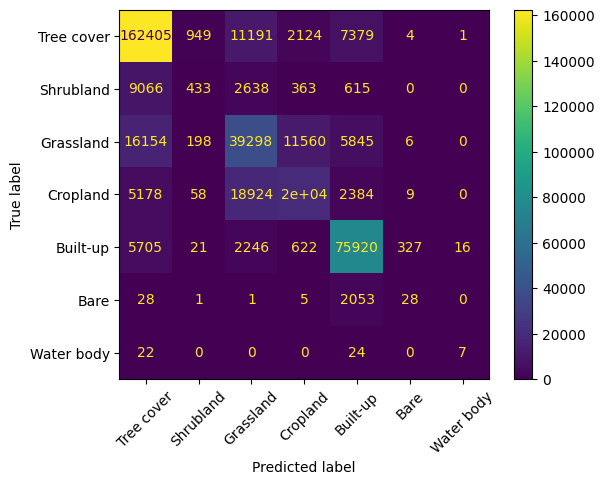

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

display_labels = ['Tree cover', 'Shrubland', 'Grassland', 'Cropland', 'Built-up', 'Bare', 'Water body']
majority_baseline =  y.value_counts(normalize=True).max()

cm = ConfusionMatrixDisplay.from_predictions(y, y_pred, xticks_rotation=45, display_labels=display_labels)
cm.figure_.savefig('confusion_matrix.png')

print(f"Majority baseline: {majority_baseline} \n")
print(classification_report(y, y_pred))